# Лабораторная работа №1
## Линейная регрессия и факторный анализ

**Цель работы:** изучение основ линейной регрессии, построение моделей регрессии, обучение моделей на реальных данных и оценка качества их работы.

В работе используется датасет **Beer Consumption — São Paulo**, содержащий сведения о погодных условиях и суточном потреблении пива.

**Целевая переменная:** `Потребление пива (л)`.

## 1. Введение

Целью данной лабораторной работы является изучение методов линейной регрессии и их применение к реальному набору данных.

В ходе работы выполняются первичный анализ и предобработка данных, исследование взаимосвязей между признаками, оценка мультиколлинеарности, построение моделей линейной, Lasso- и Ridge-регрессии, а также оценка их качества с помощью метрик RMSE, R² и MAPE.

Для проверки устойчивости моделей используется 5-кратная кросс-валидация. Дополнительно исследуется структура остатков моделей.

Для уменьшения размерности и устранения мультиколлинеарности применяется метод главных компонент (PCA) после предварительной стандартизации данных. После PCA модели строятся повторно, а полученные результаты сравниваются с моделями на исходных признаках.

## 2. Описание датасета

В работе используется набор данных **Beer Consumption — São Paulo**, посвящённый суточному потреблению пива в зависимости от погодных условий.

После удаления полностью пустых строк датасет содержит **365 наблюдений и 7 переменных**, то есть по одному наблюдению на каждый день года.

Исходный набор данных включает следующие переменные:

- `Дата` — дата наблюдения;
- `Средняя температура (°C)` — средняя температура воздуха за день;
- `Минимальная температура (°C)` — минимальная температура воздуха за день;
- `Максимальная температура (°C)` — максимальная температура воздуха за день;
- `Осадки (мм)` — количество осадков за день;
- `Выходной день` — бинарный признак, указывающий, является ли день выходным;
- `Потребление пива (л)` — объём потребления пива за день.

В качестве **целевой переменной** используется `Потребление пива (л)`.

Для построения регрессионных моделей были выбраны только количественные независимые признаки:

- средняя температура;
- минимальная температура;
- максимальная температура;
- количество осадков.

Переменная `Дата` не используется как числовой признак, а `Выходной день` исключён из моделирования, так как в данной работе рассматриваются только количественные независимые переменные.

### 2.1. Распределение признаков и целевой переменной

Для первичного анализа были построены гистограммы распределения входных признаков и целевой переменной.

Температурные признаки имеют достаточно широкий диапазон значений и отражают сезонные изменения погодных условий. Для осадков характерно большое количество наблюдений с нулевыми или небольшими значениями и небольшое число дней с интенсивными осадками.

Распределение целевой переменной показывает заметный разброс суточного потребления пива, что позволяет рассматривать задачу как задачу регрессии.

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_validate,
    GridSearchCV
)

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso
)

from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)

from sklearn.decomposition import PCA

from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

%matplotlib inline

Для анализа данных используются библиотеки `pandas` и `numpy`, для визуализации — `matplotlib` и `seaborn`.

Для построения моделей регрессии, стандартизации данных, кросс-валидации, подбора гиперпараметров и метода главных компонент используются инструменты библиотеки `scikit-learn`. Для расчёта коэффициентов VIF применяется библиотека `statsmodels`.

In [7]:
# Загрузка датасета
df = pd.read_csv(
    'Consumo_cerveja.csv',
    decimal=','
)

# Удаление полностью пустых строк
df = df.dropna(how='all').copy()

# Перевод названий столбцов на русский язык
df = df.rename(columns={
    'Data': 'Дата',
    'Temperatura Media (C)': 'Средняя температура (°C)',
    'Temperatura Minima (C)': 'Минимальная температура (°C)',
    'Temperatura Maxima (C)': 'Максимальная температура (°C)',
    'Precipitacao (mm)': 'Осадки (мм)',
    'Final de Semana': 'Выходной день',
    'Consumo de cerveja (litros)': 'Потребление пива (л)'
})

# Приведение целевой переменной к числовому типу
df['Потребление пива (л)'] = pd.to_numeric(
    df['Потребление пива (л)'],
    errors='coerce'
)

print('Размер датасета:', df.shape)

df.head()

Размер датасета: (365, 7)


,Дата,Средняя температура (°C),Минимальная температура (°C),Максимальная температура (°C),Осадки (мм),Выходной день,Потребление пива (л)
0,2015-01-01,27.30,23.9,32.5,0.0,0.0,25.461
1,2015-01-02,27.02,24.5,33.5,0.0,0.0,28.972
2,2015-01-03,24.82,22.4,29.9,0.0,1.0,30.814
3,2015-01-04,23.98,21.5,28.6,1.2,1.0,29.799
4,2015-01-05,23.82,21.0,28.3,0.0,0.0,28.900


Датасет был загружен из CSV-файла. Полностью пустые строки были удалены.

После очистки набор данных содержит **365 наблюдений и 7 переменных**. Названия столбцов были переведены на русский язык для удобства дальнейшего анализа и оформления отчёта.

Целевая переменная `Потребление пива (л)` приведена к числовому типу данных.

In [8]:
print('Информация о датасете:')
df.info()

print('\nКоличество пропущенных значений:')
print(df.isnull().sum())

print('\nКоличество полных дубликатов:')
print(df.duplicated().sum())

Информация о датасете:
<class 'pandas.core.frame.DataFrame'>
Index: 365 entries, 0 to 364
Data columns (total 7 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Дата                           365 non-null    object 
 1   Средняя температура (°C)       365 non-null    float64
 2   Минимальная температура (°C)   365 non-null    float64
 3   Максимальная температура (°C)  365 non-null    float64
 4   Осадки (мм)                    365 non-null    float64
 5   Выходной день                  365 non-null    float64
 6   Потребление пива (л)           365 non-null    float64
dtypes: float64(6), object(1)
memory usage: 22.8+ KB

Количество пропущенных значений:
Дата                             0
Средняя температура (°C)         0
Минимальная температура (°C)     0
Максимальная температура (°C)    0
Осадки (мм)                      0
Выходной день                    0
Потребление пива (л)             0
dtype:

В ходе первичного анализа были проверены типы данных, наличие пропущенных значений и полных дубликатов.

После удаления полностью пустых строк значимых пропусков в используемых числовых признаках и целевой переменной не осталось. Полные дубликаты также отсутствуют.

Таким образом, дополнительное удаление или восстановление пропущенных значений не требуется.

In [9]:
df[
    [
        'Средняя температура (°C)',
        'Минимальная температура (°C)',
        'Максимальная температура (°C)',
        'Осадки (мм)',
        'Потребление пива (л)'
    ]
].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Средняя температура (°C),365.0,21.23,3.18,12.90,19.02,21.38,23.28,28.86
Минимальная температура (°C),365.0,17.46,2.83,10.60,15.30,17.90,19.60,24.50
Максимальная температура (°C),365.0,26.61,4.32,14.50,23.80,26.90,29.40,36.50
Осадки (мм),365.0,5.20,12.42,0.00,0.00,0.00,3.20,94.80
Потребление пива (л),365.0,25.40,4.40,14.34,22.01,24.87,28.63,37.94


Описательная статистика позволяет оценить диапазон и разброс значений признаков и целевой переменной.

В дальнейшем для моделирования будут использоваться только количественные признаки: средняя, минимальная и максимальная температура, а также количество осадков. Переменные `Дата` и `Выходной день` в модель не включаются.

In [10]:
features = [
    'Средняя температура (°C)',
    'Минимальная температура (°C)',
    'Максимальная температура (°C)',
    'Осадки (мм)'
]

target = 'Потребление пива (л)'

X = df[features].copy()
y = df[target].copy()

print('Размер матрицы признаков X:', X.shape)
print('Размер целевой переменной y:', y.shape)

Размер матрицы признаков X: (365, 4)
Размер целевой переменной y: (365,)


Для построения моделей выбраны четыре количественных признака: средняя, минимальная и максимальная температура воздуха, а также количество осадков.

В качестве целевой переменной используется суточное потребление пива в литрах.

Переменная `Дата` не используется как количественный признак, а бинарная переменная `Выходной день` исключена, поскольку в данной работе рассматриваются только количественные независимые переменные.

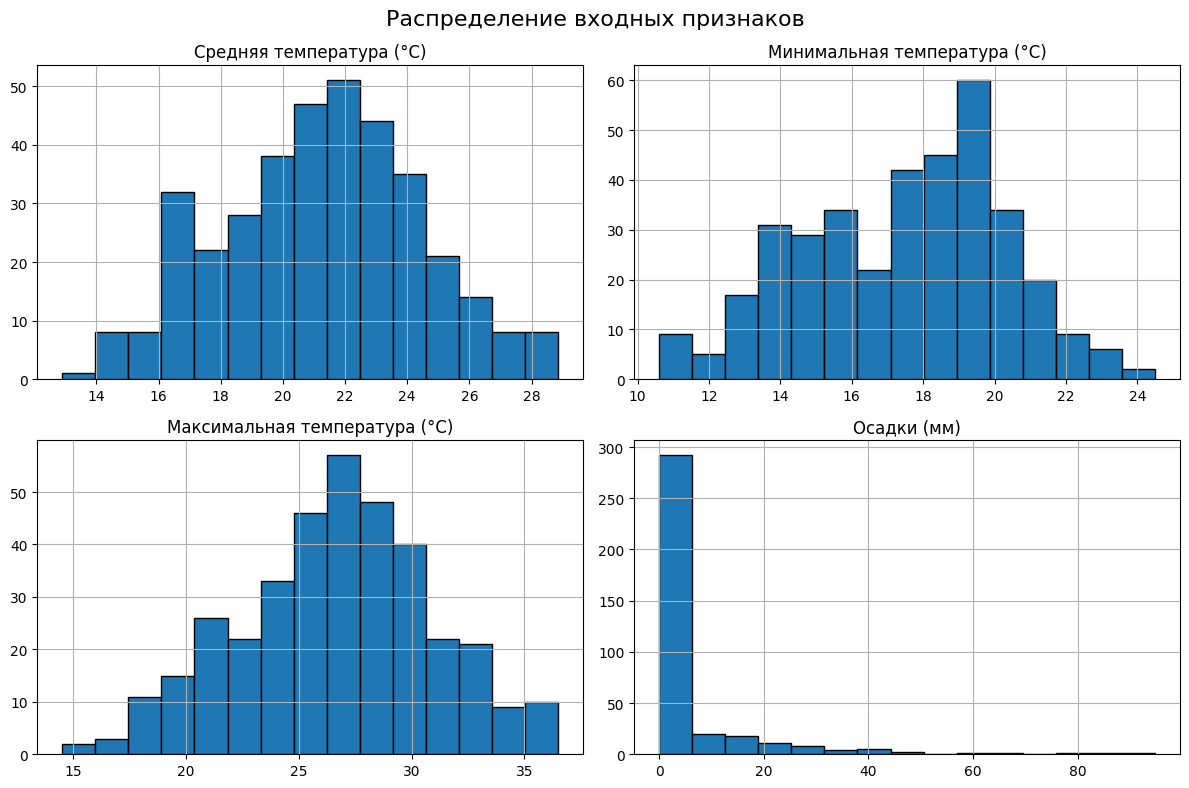

In [11]:
X.hist(
    figsize=(12, 8),
    bins=15,
    edgecolor='black'
)

plt.suptitle(
    'Распределение входных признаков',
    fontsize=16
)

plt.tight_layout()
plt.show()

In [12]:
distribution_data = pd.concat([X, y], axis=1)

distribution_stats = pd.DataFrame({
    'Среднее': distribution_data.mean(),
    'Медиана': distribution_data.median(),
    'Асимметрия': distribution_data.skew(),
    'Эксцесс': distribution_data.kurt()
})

distribution_stats.round(3)

,Среднее,Медиана,Асимметрия,Эксцесс
Средняя температура (°C),21.226,21.380,-0.049,-0.414
Минимальная температура (°C),17.461,17.900,-0.225,-0.570
Максимальная температура (°C),26.612,26.900,-0.155,-0.290
Осадки (мм),5.197,0.000,3.780,17.808
Потребление пива (л),25.401,24.867,0.270,-0.396


По значениям асимметрии и эксцесса можно сделать следующие выводы о характере распределений признаков.

Для `Средняя температура (°C)` коэффициент асимметрии равен **-0.049**, то есть распределение практически симметрично. Среднее значение (**21.226**) и медиана (**21.380**) очень близки, что подтверждает отсутствие выраженного смещения. Эксцесс равен **-0.414**, поэтому распределение немного более плоское по сравнению с нормальным.

Для `Минимальная температура (°C)` асимметрия составляет **-0.225**, что указывает на слабую левостороннюю асимметрию. Среднее (**17.461**) немного ниже медианы (**17.900**), что согласуется с отрицательной асимметрией. Эксцесс равен **-0.570**, поэтому распределение также несколько более плоское относительно нормального.

Для `Максимальная температура (°C)` коэффициент асимметрии равен **-0.155**, следовательно, распределение имеет слабую левостороннюю асимметрию и в целом близко к симметричному. Среднее значение (**26.612**) близко к медиане (**26.900**). Эксцесс составляет **-0.290**, что говорит о немного более плоском распределении по сравнению с нормальным.

Наиболее сильно отличается распределение признака `Осадки (мм)`. Коэффициент асимметрии равен **3.780**, то есть распределение имеет выраженную правостороннюю асимметрию. Медиана равна **0 мм**, тогда как среднее значение составляет **5.197 мм**, что объясняется большим количеством дней без осадков и небольшим числом дней с очень высокими значениями осадков. Эксцесс равен **17.808**, что указывает на наличие тяжёлого правого хвоста и редких экстремальных значений.

Для целевой переменной `Потребление пива (л)` коэффициент асимметрии составляет **0.270**, поэтому распределение имеет слабую правостороннюю асимметрию, но в целом остаётся близким к симметричному. Среднее значение равно **25.401 л**, медиана — **24.867 л**. Эксцесс равен **-0.396**, то есть распределение несколько более плоское по сравнению с нормальным.

Таким образом, температурные признаки и целевая переменная имеют распределения, близкие к симметричным, тогда как количество осадков характеризуется сильной правосторонней асимметрией и большим эксцессом.

На гистограммах представлены распределения четырёх входных признаков.

Визуально температурные признаки имеют относительно симметричные распределения, тогда как распределение осадков заметно смещено вправо: большинство наблюдений сосредоточено около нулевых значений, а большие значения встречаются значительно реже.

Для количественной оценки формы распределений далее рассчитаны среднее значение, медиана, коэффициент асимметрии и эксцесс.

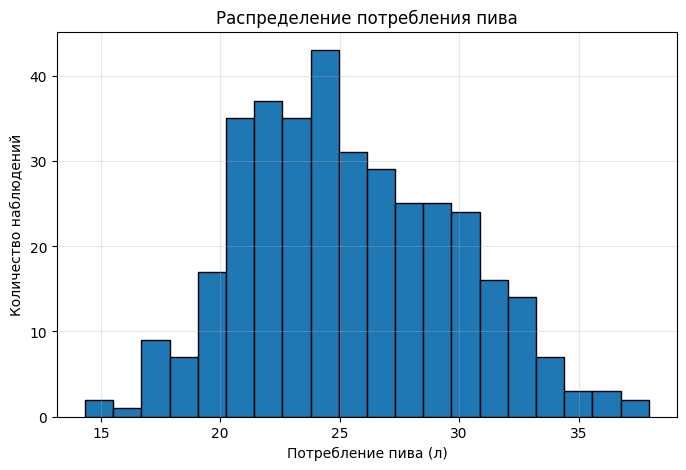

In [13]:
plt.figure(figsize=(8, 5))

plt.hist(
    y,
    bins=20,
    edgecolor='black'
)

plt.title('Распределение потребления пива')
plt.xlabel('Потребление пива (л)')
plt.ylabel('Количество наблюдений')
plt.grid(alpha=0.3)

plt.show()

Распределение целевой переменной показывает, как изменяется суточное потребление пива в рассматриваемом наборе данных.

Значения распределены по достаточно широкому диапазону, что позволяет использовать целевую переменную для решения задачи регрессии.

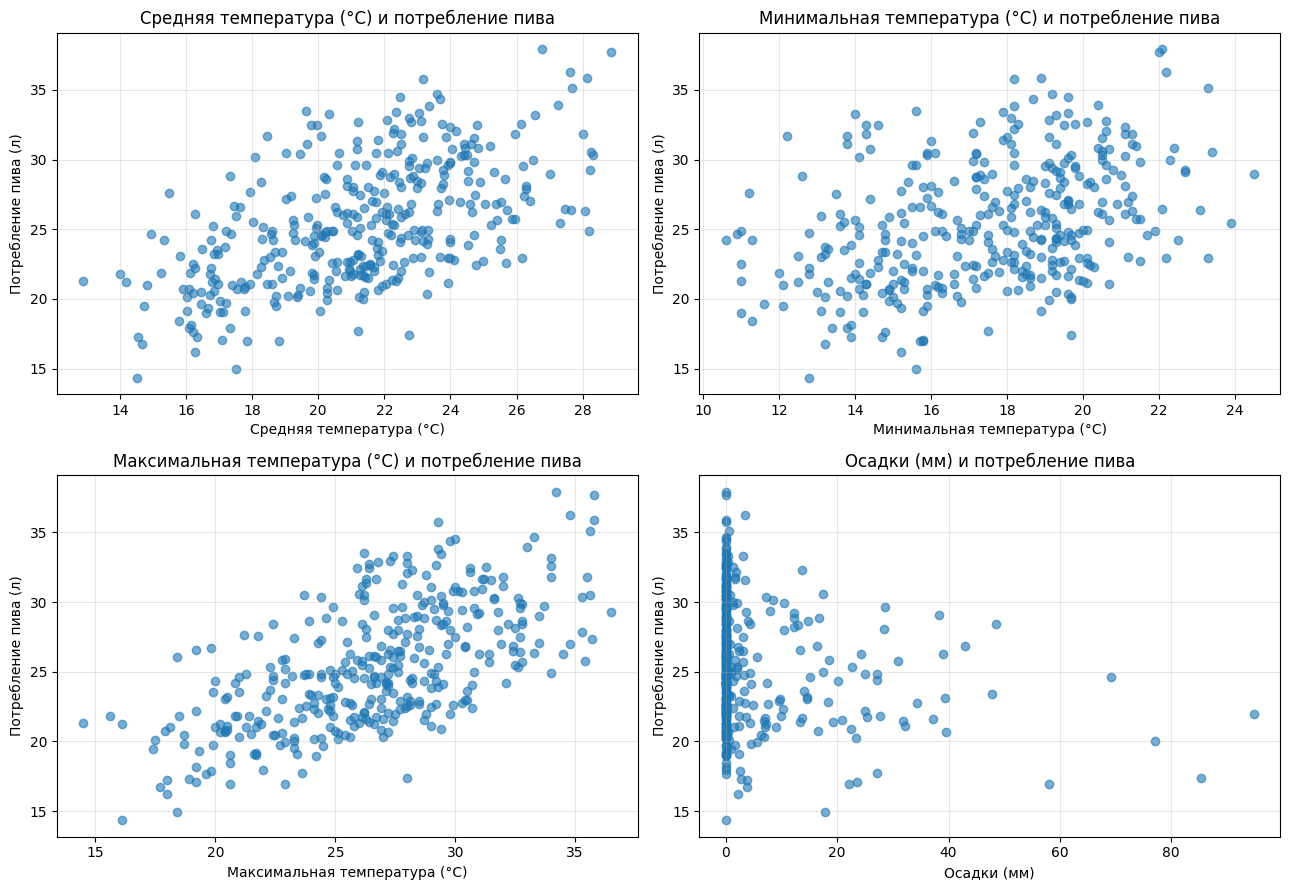

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

axes = axes.flatten()

for i, feature in enumerate(features):
    axes[i].scatter(
        X[feature],
        y,
        alpha=0.6
    )

    axes[i].set_title(
        f'{feature} и потребление пива'
    )
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('Потребление пива (л)')
    axes[i].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Диаграммы рассеяния позволяют визуально оценить зависимость целевой переменной от входных признаков.

Наиболее выраженная положительная зависимость наблюдается между потреблением пива и температурными показателями, особенно максимальной и средней температурой. При увеличении температуры потребление пива в среднем возрастает.

Для количества осадков наблюдается слабая отрицательная зависимость: при увеличении количества осадков потребление пива имеет тенденцию к снижению.

При этом зависимости не являются строго линейными, поэтому погодные характеристики объясняют лишь часть вариации целевой переменной.

In [10]:
data_corr = df[
    features + [target]
]

corr_matrix = data_corr.corr()

corr_matrix.round(2)

,Средняя температура (°C),Минимальная температура (°C),Максимальная температура (°C),Осадки (мм),Потребление пива (л)
Средняя температура (°C),1.00,0.86,0.92,0.02,0.57
Минимальная температура (°C),0.86,1.00,0.67,0.10,0.39
Максимальная температура (°C),0.92,0.67,1.00,-0.05,0.64
Осадки (мм),0.02,0.10,-0.05,1.00,-0.19
Потребление пива (л),0.57,0.39,0.64,-0.19,1.00


Матрица корреляций показывает силу линейной связи между входными признаками и целевой переменной.

Наиболее сильная положительная связь с потреблением пива наблюдается у максимальной температуры, затем у средней температуры. Осадки имеют слабую отрицательную связь с потреблением пива.

Также видно, что температурные признаки сильно коррелируют между собой, что может свидетельствовать о наличии мультиколлинеарности.

### 2.2. Корреляционный анализ

Для оценки линейных взаимосвязей между признаками и целевой переменной была построена матрица корреляций.

Наиболее сильная положительная связь с потреблением пива наблюдается у максимальной и средней температуры. Осадки имеют слабую отрицательную связь с целевой переменной.

Также температурные признаки существенно коррелируют между собой, что указывает на возможное наличие мультиколлинеарности.

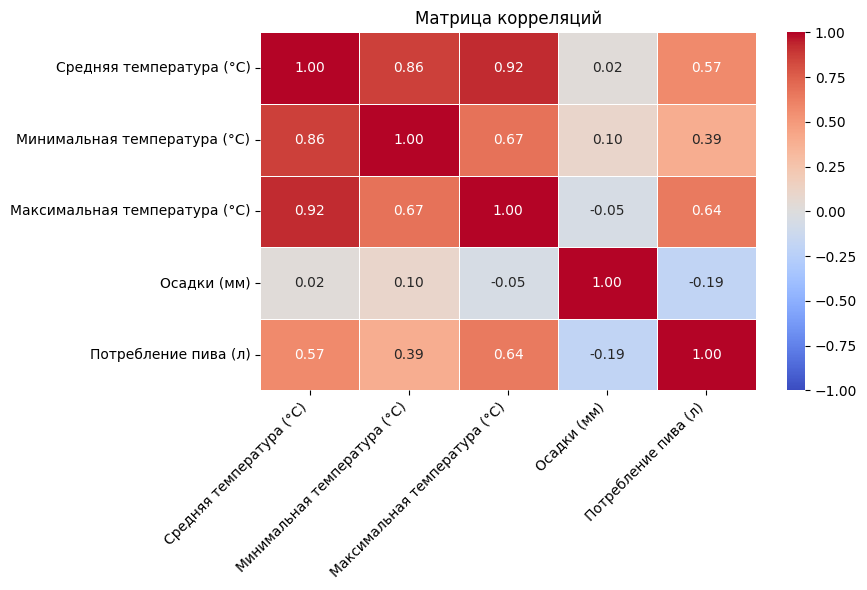

In [11]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title('Матрица корреляций')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

Матрица корреляций позволяет оценить направление и силу линейных связей между признаками и целевой переменной.

Наиболее сильные положительные связи наблюдаются между температурными признаками:

- `Средняя температура (°C)` и `Максимальная температура (°C)`: **r = 0.923** — очень сильная положительная линейная связь.
- `Средняя температура (°C)` и `Минимальная температура (°C)`: **r = 0.863** — сильная положительная линейная связь.
- `Минимальная температура (°C)` и `Максимальная температура (°C)`: **r = 0.673** — заметная положительная линейная связь.

Это означает, что при увеличении одной температурной характеристики остальные температурные показатели также обычно увеличиваются. Такие высокие значения корреляции указывают на возможную мультиколлинеарность между температурными признаками.

Связь признаков с целевой переменной `Потребление пива (л)` различается:

- `Максимальная температура (°C)` имеет наиболее выраженную положительную связь с потреблением пива: **r = 0.643**.
- `Средняя температура (°C)` также положительно связана с потреблением: **r = 0.575**.
- `Минимальная температура (°C)` имеет более слабую положительную связь: **r = 0.393**.
- `Осадки (мм)` имеют слабую отрицательную связь с потреблением пива: **r = -0.194**.

Таким образом, увеличение температуры в целом связано с увеличением потребления пива, причём сильнее всего с целевой переменной связана максимальная температура. Увеличение количества осадков, наоборот, связано с небольшим снижением потребления.

Корреляция осадков с температурными признаками близка к нулю: значения коэффициентов находятся примерно от **-0.05 до 0.10**, поэтому выраженной линейной связи между количеством осадков и температурой не наблюдается.

In [12]:
X_vif = sm.add_constant(X)

vif_data = pd.DataFrame()

vif_data['Признак'] = X_vif.columns

vif_data['VIF'] = [
    variance_inflation_factor(
        X_vif.values,
        i
    )
    for i in range(X_vif.shape[1])
]

vif_data = vif_data[
    vif_data['Признак'] != 'const'
]

vif_data.round(2)

,Признак,VIF
1,Средняя температура (°C),23.91
2,Минимальная температура (°C),6.50
3,Максимальная температура (°C),11.29
4,Осадки (мм),1.04


Полученные значения VIF подтверждают наличие мультиколлинеарности среди температурных признаков.

Для признака `Средняя температура (°C)` значение VIF составляет **23.91**. Это значительно выше порогового значения 10, поэтому данный признак характеризуется **сильной мультиколлинеарностью**.

Для `Максимальная температура (°C)` значение VIF равно **11.29**, что также указывает на **сильную мультиколлинеарность**.

Для `Минимальная температура (°C)` значение VIF составляет **6.50**. Оно превышает 5, следовательно, для данного признака наблюдается **заметная мультиколлинеарность**, однако она выражена слабее, чем для средней и максимальной температуры.

Для признака `Осадки (мм)` значение VIF равно **1.04**, что близко к 1. Следовательно, данный признак практически не связан линейной зависимостью с остальными входными переменными и проблемы мультиколлинеарности для него нет.

Таким образом, основная проблема мультиколлинеарности связана именно с температурными признаками. Этот результат согласуется с матрицей корреляций: коэффициент корреляции между средней и максимальной температурой составляет **0.92**, а между средней и минимальной — **0.86**.

Поэтому дальнейшее применение PCA является обоснованным: метод позволит заменить взаимосвязанные температурные признаки набором некоррелированных главных компонент.

### 2.3. Анализ мультиколлинеарности с помощью VIF

Для температурных признаков получены повышенные значения VIF, особенно для средней и максимальной температуры. Это подтверждает наличие мультиколлинеарности между температурными характеристиками.

Для признака `Осадки (мм)` значение VIF близко к 1, следовательно, он практически не связан линейной зависимостью с другими входными признаками.

## 3. Подготовка данных

На этапе подготовки данных были выбраны количественные входные признаки и целевая переменная, после чего данные разделены на обучающую и тестовую выборки.

Категориальные признаки в моделировании не используются, поэтому дополнительное кодирование не требуется.

### 3.1. Разделение на обучающую и тестовую выборки

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print('Обучающая выборка X_train:', X_train.shape)
print('Тестовая выборка X_test:', X_test.shape)
print('Обучающая выборка y_train:', y_train.shape)
print('Тестовая выборка y_test:', y_test.shape)

Обучающая выборка X_train: (292, 4)
Тестовая выборка X_test: (73, 4)
Обучающая выборка y_train: (292,)
Тестовая выборка y_test: (73,)


Данные были разделены на обучающую и тестовую выборки в соотношении **80/20**.

Обучающая выборка используется для обучения моделей, а тестовая — для независимой оценки качества прогнозирования.

Параметр `random_state=42` обеспечивает воспроизводимость разбиения.

### 3.2. Настройка кросс-валидации

Для дополнительной оценки устойчивости регрессионных моделей используется **5-кратная кросс-валидация**.

Данные разделяются на пять частей. На каждой итерации четыре части используются для обучения модели, а оставшаяся часть — для проверки. Процедура повторяется пять раз, после чего значения метрик усредняются.

Использование кросс-валидации позволяет получить более надёжную оценку качества модели и уменьшить зависимость результата от одного конкретного разбиения данных на обучающую и тестовую выборки.

In [14]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print('Используется 5-кратная кросс-валидация.')

Используется 5-кратная кросс-валидация.


Для дополнительной оценки устойчивости моделей используется **5-кратная кросс-валидация**.

Исходные данные разбиваются на пять частей. На каждой итерации четыре части используются для обучения модели, а оставшаяся — для проверки. Итоговые показатели качества усредняются по всем пяти итерациям.

### 3.3. Стандартизация данных

Исходные признаки имеют разные масштабы измерения, поэтому перед применением методов, чувствительных к масштабу данных, выполняется стандартизация.

Для этого используется `StandardScaler`, который преобразует признаки таким образом, чтобы их среднее значение было близко к 0, а стандартное отклонение — к 1.

Стандартизация особенно важна для Lasso- и Ridge-регрессии, а также для метода главных компонент (PCA).

In [15]:
linear_model = Pipeline([
    ('масштабирование', StandardScaler()),
    ('регрессия', LinearRegression())
])

linear_model.fit(X_train, y_train)

y_pred_linear = linear_model.predict(X_test)

Построена модель линейной регрессии. Перед обучением признаки стандартизируются с помощью `StandardScaler`.

Стандартизация приводит признаки к сопоставимому масштабу: среднее значение становится близким к 0, а стандартное отклонение — к 1.

Параметры стандартизации определяются только на обучающей выборке, после чего то же преобразование применяется к тестовой выборке. Такой подход позволяет избежать утечки информации из тестовых данных.

## 4. Ход работы
### 4.1. Линейная регрессия
После обучения линейной регрессии на обучающей выборке были получены прогнозы для тестовой выборки. Далее качество модели оценивается с помощью метрик RMSE, R² и MAPE.

In [17]:
rmse_linear = np.sqrt(
    mean_squared_error(y_test, y_pred_linear)
)

r2_linear = r2_score(
    y_test,
    y_pred_linear
)

mape_linear = mean_absolute_percentage_error(
    y_test,
    y_pred_linear
) * 100

print('Линейная регрессия')
print('RMSE:', round(rmse_linear, 3))
print('R²:', round(r2_linear, 3))
print('MAPE:', round(mape_linear, 2), '%')

Линейная регрессия
RMSE: 3.589
R²: 0.419
MAPE: 10.92 %


На тестовой выборке линейная регрессия показала следующие результаты:

- RMSE = **3.589 л**;
- R² = **0.419**;
- MAPE = **10.92%**.

Значение RMSE показывает, что среднеквадратичная ошибка прогноза составляет около **3.6 л**. Поскольку RMSE сильнее штрафует крупные ошибки, это значение характеризует общий масштаб отклонений прогнозов модели от фактического потребления.

Коэффициент детерминации R² = **0.419** означает, что модель объясняет примерно **41.9% вариации** суточного потребления пива. Следовательно, около **58.1% изменчивости** целевой переменной остаётся необъяснённой используемыми погодными признаками.

MAPE = **10.92%** означает, что прогноз модели в среднем отклоняется от фактического значения примерно на **11%**.

В целом качество модели можно оценить как **умеренное**: относительная ошибка прогноза невелика, однако модель объясняет менее половины изменчивости потребления пива. Это указывает на наличие других факторов, влияющих на потребление и не включённых в модель.

Для линейной регрессии получены значения RMSE = **3.589**, R² = **0.419** и MAPE = **10.92%**.

Значение R² показывает, что модель объясняет около **41.9%** вариации суточного потребления пива. Средняя относительная ошибка прогноза составляет около **10.9%**.

Таким образом, линейная модель обладает умеренной объясняющей способностью: погодные признаки влияют на потребление пива, однако не описывают его полностью.

In [18]:
cv_linear = cross_validate(
    linear_model,
    X,
    y,
    cv=cv,
    scoring={
        'rmse': 'neg_root_mean_squared_error',
        'r2': 'r2',
        'mape': 'neg_mean_absolute_percentage_error'
    }
)

print('Линейная регрессия — 5-кратная кросс-валидация')
print(
    'Средний RMSE:',
    round(-cv_linear['test_rmse'].mean(), 3)
)
print(
    'Средний R²:',
    round(cv_linear['test_r2'].mean(), 3)
)
print(
    'Средний MAPE:',
    round(-cv_linear['test_mape'].mean() * 100, 2),
    '%'
)

Линейная регрессия — 5-кратная кросс-валидация
Средний RMSE: 3.356
Средний R²: 0.387
Средний MAPE: 11.11 %


По результатам 5-кратной кросс-валидации получены средние значения:

- RMSE = **3.356 л**;
- R² = **0.387**;
- MAPE = **11.11%**.

Среднее значение R² показывает, что на различных разбиениях данных модель объясняет около **38.7% вариации** потребления пива. Таким образом, её объясняющая способность остаётся умеренной.

MAPE около **11.1%** означает, что средняя относительная ошибка прогноза при кросс-валидации практически совпадает с ошибкой на тестовой выборке (**10.92%**).

Также близки значения RMSE: **3.589 л** на тестовой выборке и **3.356 л** при кросс-валидации. Существенного ухудшения качества на разных разбиениях данных не наблюдается, поэтому выраженных признаков переобучения модели нет.

Таким образом, линейная регрессия демонстрирует достаточно стабильное, но умеренное качество прогнозирования.

### 4.2. Lasso-регрессия

In [19]:
lasso_search = Pipeline([
    ('масштабирование', StandardScaler()),
    ('регрессия', Lasso(max_iter=10000))
])

param_grid_lasso = {
    'регрессия__alpha': [
        0.001, 0.01, 0.05, 0.1, 0.5, 1, 5, 10
    ]
}

grid_search_lasso = GridSearchCV(
    lasso_search,
    param_grid_lasso,
    cv=5,
    scoring='neg_root_mean_squared_error'
)

grid_search_lasso.fit(X_train, y_train)

best_alpha_lasso = grid_search_lasso.best_params_[
    'регрессия__alpha'
]

print('Лучшее alpha для Lasso:', best_alpha_lasso)
print(
    'Лучший RMSE при подборе:',
    round(-grid_search_lasso.best_score_, 3)
)

Лучшее alpha для Lasso: 0.01
Лучший RMSE при подборе: 3.275


Подбор коэффициента регуляризации с помощью `GridSearchCV` показал, что оптимальным для Lasso-регрессии является значение `alpha = 0.01`.

Небольшое значение `alpha` означает, что сильная L1-регуляризация для данного набора данных не требуется. Это связано с тем, что слишком сильное зануление коэффициентов могло бы привести к потере полезной информации.

Лучшее значение RMSE при подборе составило около **3.275 л**, что близко к результату обычной линейной регрессии.

In [20]:
lasso_model = grid_search_lasso.best_estimator_

y_pred_lasso = lasso_model.predict(X_test)

rmse_lasso = np.sqrt(
    mean_squared_error(y_test, y_pred_lasso)
)

r2_lasso = r2_score(
    y_test,
    y_pred_lasso
)

mape_lasso = mean_absolute_percentage_error(
    y_test,
    y_pred_lasso
) * 100

print('Lasso-регрессия')
print('alpha:', best_alpha_lasso)
print('RMSE:', round(rmse_lasso, 3))
print('R²:', round(r2_lasso, 3))
print('MAPE:', round(mape_lasso, 2), '%')

Lasso-регрессия
alpha: 0.01
RMSE: 3.585
R²: 0.42
MAPE: 10.9 %


Для Lasso-регрессии рассчитаны показатели RMSE, R² и MAPE на тестовой выборке.

Полученные значения позволяют сравнить качество Lasso с обычной линейной регрессией и определить, даёт ли L1-регуляризация улучшение качества прогнозирования.

На тестовой выборке Lasso-регрессия показала следующие результаты:

- RMSE = **3.585 л**;
- R² = **0.420**;
- MAPE = **10.90%**.

Среднеквадратичная ошибка прогноза составляет около **3.59 л**, то есть общий масштаб ошибок практически совпадает с обычной линейной регрессией.

Значение R² = **0.420** означает, что модель объясняет около **42.0% вариации** суточного потребления пива. Это немного выше, чем у обычной линейной регрессии, где R² = **0.419**.

MAPE = **10.90%** означает, что средняя относительная ошибка прогноза составляет примерно **10.9%**.

По сравнению с обычной линейной регрессией улучшение минимально: RMSE уменьшился с **3.589** до **3.585 л**, R² увеличился с **0.419** до **0.420**, а MAPE снизился с **10.92%** до **10.90%**.

Следовательно, Lasso-регрессия формально показывает лучший результат на тестовой выборке, однако различие настолько мало, что практическое преимущество перед обычной линейной регрессией незначительно.

In [21]:
lasso_cv_model = Pipeline([
    ('масштабирование', StandardScaler()),
    ('регрессия', Lasso(
        alpha=best_alpha_lasso,
        max_iter=10000
    ))
])

cv_lasso = cross_validate(
    lasso_cv_model,
    X,
    y,
    cv=cv,
    scoring={
        'rmse': 'neg_root_mean_squared_error',
        'r2': 'r2',
        'mape': 'neg_mean_absolute_percentage_error'
    }
)

print('Lasso — 5-кратная кросс-валидация')
print(
    'Средний RMSE:',
    round(-cv_lasso['test_rmse'].mean(), 3)
)
print(
    'Средний R²:',
    round(cv_lasso['test_r2'].mean(), 3)
)
print(
    'Средний MAPE:',
    round(-cv_lasso['test_mape'].mean() * 100, 2),
    '%'
)

Lasso — 5-кратная кросс-валидация
Средний RMSE: 3.351
Средний R²: 0.389
Средний MAPE: 11.1 %


По результатам 5-кратной кросс-валидации для Lasso-регрессии получены:

- RMSE = **3.351 л**;
- R² = **0.389**;
- MAPE = **11.10%**.

Среднее значение R² показывает, что на различных разбиениях данных модель объясняет около **38.9% вариации** целевой переменной.

MAPE около **11.1%** практически совпадает с результатом на тестовой выборке (**10.90%**), а RMSE при кросс-валидации (**3.351 л**) также близок к тестовому значению (**3.585 л**).

Это говорит о том, что модель демонстрирует достаточно стабильное качество на разных подвыборках и не имеет выраженных признаков переобучения.

В целом качество Lasso-регрессии можно оценить как **умеренное**: модель имеет относительно небольшую процентную ошибку, но объясняет менее половины вариации потребления пива.

### 4.3. Ridge-регрессия

In [22]:
ridge_search = Pipeline([
    ('масштабирование', StandardScaler()),
    ('регрессия', Ridge())
])

param_grid_ridge = {
    'регрессия__alpha': [
        0.001, 0.01, 0.1, 1, 10, 100
    ]
}

grid_search_ridge = GridSearchCV(
    ridge_search,
    param_grid_ridge,
    cv=5,
    scoring='neg_root_mean_squared_error'
)

grid_search_ridge.fit(X_train, y_train)

best_alpha_ridge = grid_search_ridge.best_params_[
    'регрессия__alpha'
]

print('Лучшее alpha для Ridge:', best_alpha_ridge)
print(
    'Лучший RMSE при подборе:',
    round(-grid_search_ridge.best_score_, 3)
)

Лучшее alpha для Ridge: 10
Лучший RMSE при подборе: 3.274


Для Ridge-регрессии коэффициент регуляризации `alpha` также подбирается с помощью `GridSearchCV`.

Ridge использует L2-регуляризацию, которая уменьшает величину коэффициентов модели и особенно полезна при наличии мультиколлинеарности между признаками.

По результатам подбора оптимальным значением коэффициента регуляризации для Ridge-регрессии оказалось **alpha = 10**.

Лучшее значение RMSE при подборе составило **3.274**. В отличие от Lasso, для Ridge потребовалась более сильная регуляризация, что связано с выраженной мультиколлинеарностью между температурными признаками.

L2-регуляризация не обнуляет коэффициенты полностью, а уменьшает их величину, благодаря чему модель становится более устойчивой при наличии взаимосвязанных признаков.

In [23]:
ridge_model = grid_search_ridge.best_estimator_

y_pred_ridge = ridge_model.predict(X_test)

rmse_ridge = np.sqrt(
    mean_squared_error(y_test, y_pred_ridge)
)

r2_ridge = r2_score(
    y_test,
    y_pred_ridge
)

mape_ridge = mean_absolute_percentage_error(
    y_test,
    y_pred_ridge
) * 100

print('Гребневая регрессия')
print('alpha:', best_alpha_ridge)
print('RMSE:', round(rmse_ridge, 3))
print('R²:', round(r2_ridge, 3))
print('MAPE:', round(mape_ridge, 2), '%')

Гребневая регрессия
alpha: 10
RMSE: 3.608
R²: 0.413
MAPE: 10.91 %


На тестовой выборке Ridge-регрессия показала следующие результаты:

- RMSE = **3.608 л**;
- R² = **0.413**;
- MAPE = **10.91%**.

Среднеквадратичная ошибка прогноза составляет около **3.61 л**, то есть общий масштаб ошибок немного выше, чем у линейной и Lasso-регрессии.

Значение R² = **0.413** означает, что модель объясняет около **41.3% вариации** суточного потребления пива.

MAPE = **10.91%** показывает, что средняя относительная ошибка прогноза составляет примерно **10.9%**.

По сравнению с обычной линейной регрессией RMSE увеличился с **3.589** до **3.608 л**, а R² снизился с **0.419** до **0.413**. Следовательно, использование Ridge-регуляризации не привело к улучшению качества прогнозирования.

При этом Ridge может быть полезен при мультиколлинеарности, так как L2-регуляризация уменьшает чувствительность коэффициентов к сильной взаимосвязи между признаками.

In [24]:
ridge_cv_model = Pipeline([
    ('масштабирование', StandardScaler()),
    ('регрессия', Ridge(alpha=best_alpha_ridge))
])

cv_ridge = cross_validate(
    ridge_cv_model,
    X,
    y,
    cv=cv,
    scoring={
        'rmse': 'neg_root_mean_squared_error',
        'r2': 'r2',
        'mape': 'neg_mean_absolute_percentage_error'
    }
)

print('Ridge — 5-кратная кросс-валидация')
print(
    'Средний RMSE:',
    round(-cv_ridge['test_rmse'].mean(), 3)
)
print(
    'Средний R²:',
    round(cv_ridge['test_r2'].mean(), 3)
)
print(
    'Средний MAPE:',
    round(-cv_ridge['test_mape'].mean() * 100, 2),
    '%'
)

Ridge — 5-кратная кросс-валидация
Средний RMSE: 3.352
Средний R²: 0.388
Средний MAPE: 11.12 %


По результатам 5-кратной кросс-валидации для Ridge-регрессии получены:

- RMSE = **3.352 л**;
- R² = **0.388**;
- MAPE = **11.12%**.

Среднее значение R² показывает, что модель объясняет около **38.8% вариации** целевой переменной на различных разбиениях данных.

MAPE около **11.1%** и RMSE около **3.35 л** близки к результатам на тестовой выборке, поэтому выраженного переобучения не наблюдается.

По качеству Ridge-регрессия практически не отличается от Linear и Lasso. Однако на тестовой выборке её R² немного ниже, а RMSE немного выше, поэтому по точности она оказалась чуть слабее.

### 4.4. Анализ остатков моделей

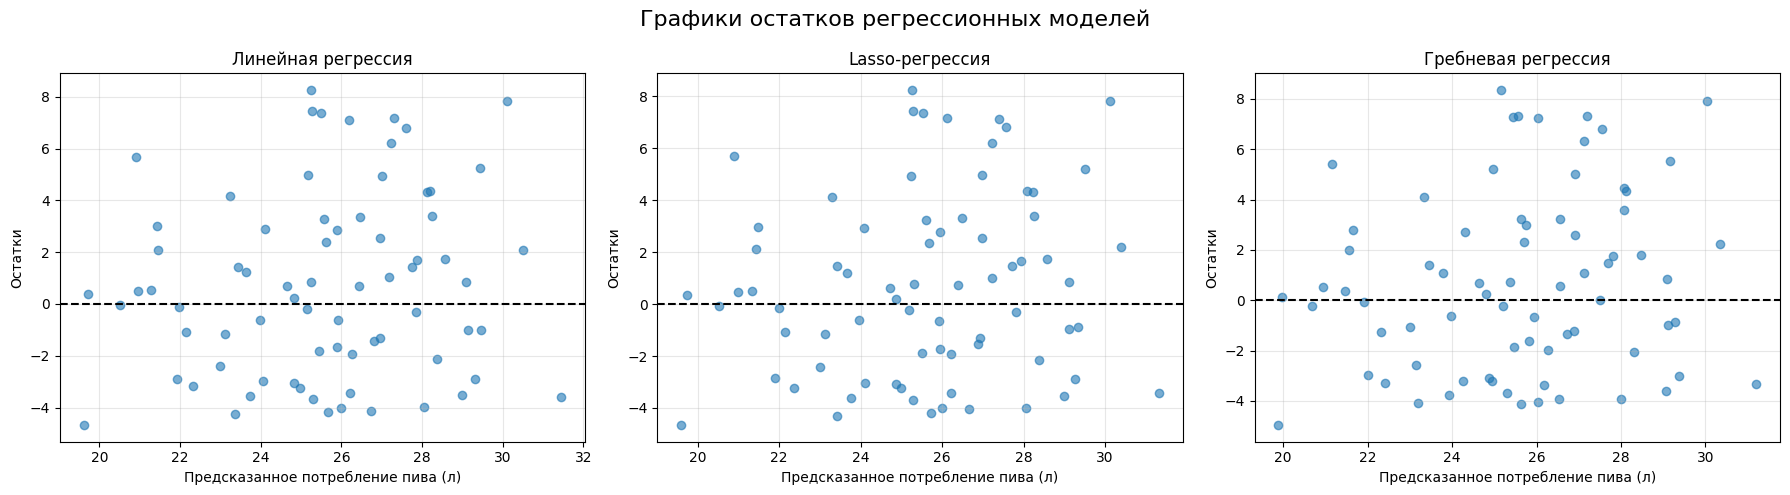

In [27]:
# Расчёт остатков
residuals_linear = y_test - y_pred_linear
residuals_lasso = y_test - y_pred_lasso
residuals_ridge = y_test - y_pred_ridge

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

models_residuals = [
    (
        y_pred_linear,
        residuals_linear,
        'Линейная регрессия'
    ),
    (
        y_pred_lasso,
        residuals_lasso,
        'Lasso-регрессия'
    ),
    (
        y_pred_ridge,
        residuals_ridge,
        'Гребневая регрессия'
    )
]

for ax, (predictions, residuals, title) in zip(
    axes,
    models_residuals
):
    ax.scatter(
        predictions,
        residuals,
        alpha=0.6
    )

    ax.axhline(
        y=0,
        color='black',
        linestyle='--',
        linewidth=1.5
    )

    ax.set_title(title)
    ax.set_xlabel('Предсказанное потребление пива (л)')
    ax.set_ylabel('Остатки')
    ax.grid(alpha=0.3)

plt.suptitle(
    'Графики остатков регрессионных моделей',
    fontsize=16
)

plt.tight_layout()
plt.show()

На графиках показана зависимость остатков от предсказанных значений для линейной, Lasso- и Ridge-регрессии.

Во всех трёх случаях остатки располагаются как выше, так и ниже горизонтальной линии `y = 0`, без выраженной систематической кривизны. Это означает, что модели в целом не имеют явного направления смещения: ошибки не сосредоточены только в положительной или только в отрицательной области.

Также не наблюдается выраженной воронкообразной формы облака точек. Разброс остатков остаётся примерно сопоставимым при различных предсказанных значениях, поэтому сильных признаков гетероскедастичности визуально не выявлено.

Для всех трёх моделей структура остатков практически одинакова, что согласуется с близкими значениями RMSE, R² и MAPE. Это показывает, что добавление L1- или L2-регуляризации существенно не изменило характер ошибок модели.

При этом на графиках присутствуют отдельные наблюдения с относительно большими по модулю остатками. Следовательно, модель хуже предсказывает некоторые отдельные дни, вероятно из-за факторов, которые не входят в текущий набор признаков.

Таким образом, по графикам остатков можно сделать вывод о приблизительной гомоскедастичности ошибок и отсутствии выраженной систематической структуры остатков, однако отдельные крупные ошибки присутствуют.

### 4.5. Устранение мультиколлинеарности методом PCA

In [28]:
scaler_pca = StandardScaler()

X_train_scaled = scaler_pca.fit_transform(X_train)
X_test_scaled = scaler_pca.transform(X_test)

print('Размер X_train после стандартизации:', X_train_scaled.shape)
print('Размер X_test после стандартизации:', X_test_scaled.shape)

Размер X_train после стандартизации: (292, 4)
Размер X_test после стандартизации: (73, 4)


### Стандартизация данных

Перед применением метода главных компонент была выполнена стандартизация входных признаков с помощью `StandardScaler`.

Это необходимо, поскольку исходные признаки имеют различные масштабы измерения. После стандартизации каждый признак имеет среднее значение, близкое к 0, и стандартное отклонение, близкое к 1.

Параметры стандартизации рассчитывались только на обучающей выборке, после чего те же преобразования были применены к тестовой выборке. Такой подход позволяет избежать утечки информации из тестовых данных.

In [29]:
pca_full = PCA()

X_train_pca_full = pca_full.fit_transform(
    X_train_scaled
)

explained_variance = (
    pca_full.explained_variance_ratio_
)

cumulative_variance = np.cumsum(
    explained_variance
)

for i, (variance, cumulative) in enumerate(
    zip(explained_variance, cumulative_variance),
    start=1
):
    print(
        f'Главная компонента {i}: '
        f'{variance * 100:.2f}% '
        f'| накопленная дисперсия: '
        f'{cumulative * 100:.2f}%'
    )

Главная компонента 1: 66.44% | накопленная дисперсия: 66.44%
Главная компонента 2: 25.58% | накопленная дисперсия: 92.02%
Главная компонента 3: 7.34% | накопленная дисперсия: 99.36%
Главная компонента 4: 0.64% | накопленная дисперсия: 100.00%


#### Анализ объяснённой дисперсии

Метод главных компонент был применён к стандартизированным данным без предварительного ограничения числа компонент.

Первая главная компонента объясняет наибольшую часть дисперсии исходных признаков. При добавлении второй и третьей компонент накопленная доля объяснённой дисперсии существенно возрастает.

Первые три главные компоненты сохраняют практически всю информацию исходного пространства признаков, поэтому далее размерность данных будет уменьшена с 4 до 3 компонент.

#### График каменистой осыпи

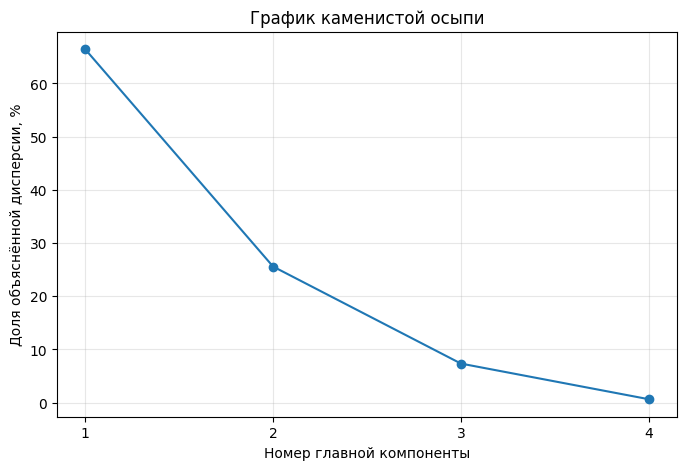

In [30]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(explained_variance) + 1),
    explained_variance * 100,
    marker='o'
)

plt.xlabel('Номер главной компоненты')
plt.ylabel('Доля объяснённой дисперсии, %')
plt.title('График каменистой осыпи')
plt.xticks(
    range(1, len(explained_variance) + 1)
)
plt.grid(alpha=0.3)

plt.show()

График каменистой осыпи показывает, какую долю общей дисперсии объясняет каждая главная компонента.

Первая главная компонента объясняет около **66.44%** дисперсии исходных признаков. Вторая компонента добавляет ещё около **25.58%**, поэтому первые две компоненты совместно сохраняют примерно **92.02%** информации.

Третья компонента объясняет ещё около **7.34%**, после чего суммарная объяснённая дисперсия достигает примерно **99.36%**.

Четвёртая компонента содержит менее **1%** общей дисперсии, поэтому её вклад в описание данных незначителен.

Следовательно, основная информация исходных четырёх признаков сосредоточена в первых трёх главных компонентах.

#### Накопленная объяснённая дисперсия

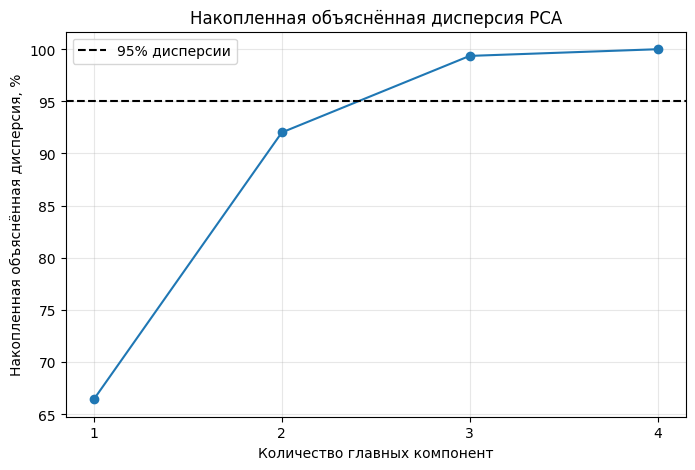

In [31]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance * 100,
    marker='o'
)

plt.axhline(
    y=95,
    color='black',
    linestyle='--',
    label='95% дисперсии'
)

plt.xlabel('Количество главных компонент')
plt.ylabel('Накопленная объяснённая дисперсия, %')
plt.title('Накопленная объяснённая дисперсия PCA')

plt.xticks(
    range(1, len(cumulative_variance) + 1)
)

plt.grid(alpha=0.3)
plt.legend()

plt.show()

По графику накопленной объяснённой дисперсии видно, что использование только двух главных компонент сохраняет около **92.02%** информации, что ниже выбранного порога **95%**.

При использовании трёх главных компонент сохраняется около **99.36%** общей дисперсии, то есть теряется менее **1%** информации.

Поэтому для дальнейшего моделирования выбраны **3 главные компоненты**. Это позволяет уменьшить размерность пространства признаков с **4 до 3**, сохранив практически всю информацию исходного набора данных.

In [32]:
pca = PCA(n_components=3)

X_train_pca = pca.fit_transform(
    X_train_scaled
)

X_test_pca = pca.transform(
    X_test_scaled
)

print(
    'Размер X_train после PCA:',
    X_train_pca.shape
)

print(
    'Размер X_test после PCA:',
    X_test_pca.shape
)

print(
    'Сохранённая дисперсия:',
    round(
        pca.explained_variance_ratio_.sum() * 100,
        2
    ),
    '%'
)

Размер X_train после PCA: (292, 3)
Размер X_test после PCA: (73, 3)
Сохранённая дисперсия: 99.36 %


Для дальнейшего моделирования были выбраны **3 главные компоненты**.

Таким образом, размерность входного пространства была уменьшена с 4 исходных признаков до 3 главных компонент, при этом сохраняется около 99% общей дисперсии данных.

Поскольку главные компоненты являются взаимно ортогональными, линейная зависимость между ними отсутствует. Следовательно, применение PCA позволяет устранить мультиколлинеарность исходных признаков.

In [33]:
pca_columns = [
    'Главная компонента 1',
    'Главная компонента 2',
    'Главная компонента 3'
]

X_train_pca_df = pd.DataFrame(
    X_train_pca,
    columns=pca_columns
)

pca_corr = X_train_pca_df.corr()

pca_corr.round(2)

,Главная компонента 1,Главная компонента 2,Главная компонента 3
Главная компонента 1,1.0,0.0,0.0
Главная компонента 2,0.0,1.0,-0.0
Главная компонента 3,0.0,-0.0,1.0


Матрица корреляций главных компонент показывает, что коэффициенты корреляции между различными компонентами практически равны нулю.

Это подтверждает, что после применения PCA мультиколлинеарность между входными признаками была устранена.

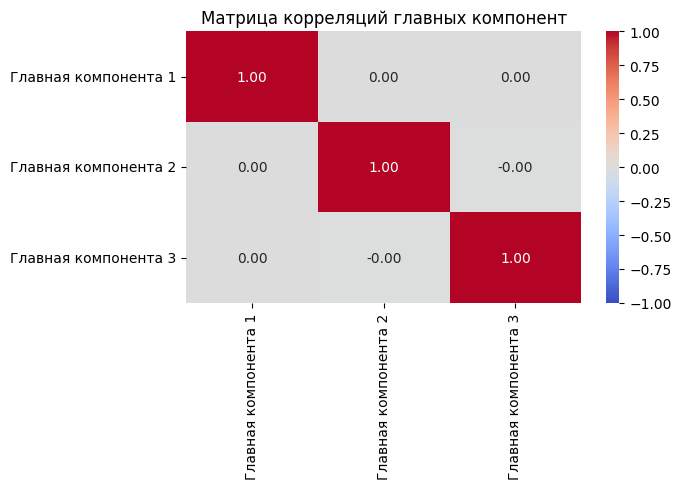

In [34]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    pca_corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0
)

plt.title(
    'Матрица корреляций главных компонент'
)

plt.tight_layout()
plt.show()

После применения PCA коэффициенты корреляции между главными компонентами практически равны **0**.

В частности, корреляции между `Главная компонента 1`, `Главная компонента 2` и `Главная компонента 3` находятся на уровне **0.00** с учётом округления.

Это означает, что полученные главные компоненты являются взаимно некоррелированными. Следовательно, выраженная линейная зависимость, которая присутствовала между исходными температурными признаками, после PCA устранена.

Для сравнения, до PCA коэффициенты корреляции между температурными признаками достигали **0.86–0.92**, а значения VIF для средней и максимальной температуры составляли **23.91** и **11.29** соответственно.

Таким образом, PCA действительно решил проблему мультиколлинеарности: вместо взаимосвязанных исходных признаков модель далее использует три некоррелированные главные компоненты.

### 4.6. Регрессионные модели после PCA

После устранения мультиколлинеарности исходные признаки были заменены тремя главными компонентами.

На преобразованных данных повторно строятся линейная, Lasso- и Ridge-регрессии. Для всех моделей рассчитываются те же показатели качества: RMSE, R² и MAPE, а также проводится 5-кратная кросс-валидация.

Это позволяет сравнить качество моделей до и после уменьшения размерности признакового пространства.
#### 4.6.1. Линейная регрессия после PCA

In [35]:
linear_pca_model = LinearRegression()

linear_pca_model.fit(
    X_train_pca,
    y_train
)

y_pred_linear_pca = linear_pca_model.predict(
    X_test_pca
)

rmse_linear_pca = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_linear_pca
    )
)

r2_linear_pca = r2_score(
    y_test,
    y_pred_linear_pca
)

mape_linear_pca = mean_absolute_percentage_error(
    y_test,
    y_pred_linear_pca
) * 100

print('Линейная регрессия после PCA')
print('RMSE:', round(rmse_linear_pca, 3))
print('R²:', round(r2_linear_pca, 3))
print('MAPE:', round(mape_linear_pca, 2), '%')

Линейная регрессия после PCA
RMSE: 3.605
R²: 0.414
MAPE: 10.94 %


После применения PCA линейная регрессия показала на тестовой выборке:

- RMSE = **3.605 л**;
- R² = **0.414**;
- MAPE = **10.94%**.

Среднеквадратичная ошибка составляет около **3.61 л**, а средняя относительная ошибка — около **10.94%**.

Значение R² = **0.414** означает, что модель объясняет около **41.4% вариации** суточного потребления пива.

По сравнению с линейной регрессией на исходных признаках качество немного снизилось: RMSE увеличился с **3.589** до **3.605 л**, а R² уменьшился с **0.419** до **0.414**. MAPE практически не изменился: **10.92%** до PCA и **10.94%** после PCA.

Следовательно, PCA позволил устранить мультиколлинеарность и уменьшить размерность данных, но не улучшил точность линейной регрессии.

In [36]:
linear_pca_pipeline = Pipeline([
    ('масштабирование', StandardScaler()),
    ('PCA', PCA(n_components=3)),
    ('регрессия', LinearRegression())
])

cv_linear_pca = cross_validate(
    linear_pca_pipeline,
    X,
    y,
    cv=cv,
    scoring={
        'rmse': 'neg_root_mean_squared_error',
        'r2': 'r2',
        'mape': 'neg_mean_absolute_percentage_error'
    }
)

print('Линейная регрессия + PCA — 5-кратная кросс-валидация')
print(
    'Средний RMSE:',
    round(-cv_linear_pca['test_rmse'].mean(), 3)
)
print(
    'Средний R²:',
    round(cv_linear_pca['test_r2'].mean(), 3)
)
print(
    'Средний MAPE:',
    round(-cv_linear_pca['test_mape'].mean() * 100, 2),
    '%'
)

Линейная регрессия + PCA — 5-кратная кросс-валидация
Средний RMSE: 3.35
Средний R²: 0.389
Средний MAPE: 11.14 %


По результатам 5-кратной кросс-валидации линейной регрессии после PCA получены:

- RMSE = **3.350 л**;
- R² = **0.389**;
- MAPE = **11.14%**.

Модель в среднем объясняет около **38.9% вариации** целевой переменной на разных разбиениях данных.

Значения MAPE на тестовой выборке (**10.94%**) и при кросс-валидации (**11.14%**) близки. Аналогично, существенного расхождения по RMSE не наблюдается.

Это показывает, что модель после PCA остаётся стабильной и не демонстрирует выраженного переобучения, однако её объясняющая способность остаётся умеренной.

#### 4.6.2. Lasso-регрессия после PCA

In [37]:
lasso_pca_search = Pipeline([
    ('масштабирование', StandardScaler()),
    ('PCA', PCA(n_components=3)),
    ('регрессия', Lasso(max_iter=10000))
])

param_grid_lasso_pca = {
    'регрессия__alpha': [
        0.001, 0.01, 0.05, 0.1, 0.5, 1, 5, 10
    ]
}

grid_search_lasso_pca = GridSearchCV(
    lasso_pca_search,
    param_grid_lasso_pca,
    cv=5,
    scoring='neg_root_mean_squared_error'
)

grid_search_lasso_pca.fit(
    X_train,
    y_train
)

best_alpha_lasso_pca = (
    grid_search_lasso_pca.best_params_[
        'регрессия__alpha'
    ]
)

print(
    'Лучшее alpha для Lasso после PCA:',
    best_alpha_lasso_pca
)

print(
    'Лучший RMSE при подборе:',
    round(-grid_search_lasso_pca.best_score_, 3)
)

Лучшее alpha для Lasso после PCA: 0.001
Лучший RMSE при подборе: 3.268


После выбора `alpha = 0.001` модель была проверена на отдельной тестовой выборке.

Получены следующие значения:

- RMSE = **3.605 л**;
- R² = **0.414**;
- MAPE = **10.94%**.

Значение RMSE на тестовой выборке выше, чем средний RMSE при подборе параметра (**3.268 л**), что нормально, поскольку тестовая выборка не использовалась при выборе `alpha`.

In [38]:
lasso_pca_model = (
    grid_search_lasso_pca.best_estimator_
)

y_pred_lasso_pca = lasso_pca_model.predict(
    X_test
)

rmse_lasso_pca = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_lasso_pca
    )
)

r2_lasso_pca = r2_score(
    y_test,
    y_pred_lasso_pca
)

mape_lasso_pca = mean_absolute_percentage_error(
    y_test,
    y_pred_lasso_pca
) * 100

print('Lasso-регрессия после PCA')
print('alpha:', best_alpha_lasso_pca)
print('RMSE:', round(rmse_lasso_pca, 3))
print('R²:', round(r2_lasso_pca, 3))
print('MAPE:', round(mape_lasso_pca, 2), '%')

Lasso-регрессия после PCA
alpha: 0.001
RMSE: 3.605
R²: 0.414
MAPE: 10.94 %


После PCA для Lasso-регрессии оптимальным оказалось значение `alpha = 0.001`.

На тестовой выборке получены:

- RMSE = **3.605 л**;
- R² = **0.414**;
- MAPE = **10.94%**.

По сравнению с Lasso на исходных признаках качество немного снизилось: до PCA RMSE составлял **3.585 л**, R² = **0.420**, MAPE = **10.90%**, а после PCA значения стали **3.605 л**, **0.414** и **10.94%** соответственно.

Таким образом, после устранения мультиколлинеарности L1-регуляризация практически не даёт дополнительного преимущества. Это согласуется с очень малым оптимальным значением `alpha = 0.001`.

In [39]:
cv_lasso_pca = cross_validate(
    lasso_pca_model,
    X,
    y,
    cv=cv,
    scoring={
        'rmse': 'neg_root_mean_squared_error',
        'r2': 'r2',
        'mape': 'neg_mean_absolute_percentage_error'
    }
)

print('Lasso + PCA — 5-кратная кросс-валидация')
print(
    'Средний RMSE:',
    round(-cv_lasso_pca['test_rmse'].mean(), 3)
)
print(
    'Средний R²:',
    round(cv_lasso_pca['test_r2'].mean(), 3)
)
print(
    'Средний MAPE:',
    round(-cv_lasso_pca['test_mape'].mean() * 100, 2),
    '%'
)

Lasso + PCA — 5-кратная кросс-валидация
Средний RMSE: 3.35
Средний R²: 0.389
Средний MAPE: 11.14 %


По результатам 5-кратной кросс-валидации Lasso после PCA получены RMSE = **3.350 л**, R² = **0.389** и MAPE = **11.14%**.

Эти значения практически совпадают с результатами обычной линейной регрессии после PCA. Это показывает, что после перехода к некоррелированным главным компонентам влияние L1-регуляризации становится минимальным.

Качество модели остаётся умеренным, а признаков выраженного переобучения не наблюдается.

#### 4.6.3. Ridge-регрессия после PCA

In [40]:
ridge_pca_search = Pipeline([
    ('масштабирование', StandardScaler()),
    ('PCA', PCA(n_components=3)),
    ('регрессия', Ridge())
])

param_grid_ridge_pca = {
    'регрессия__alpha': [
        0.001, 0.01, 0.1, 1, 10, 100
    ]
}

grid_search_ridge_pca = GridSearchCV(
    ridge_pca_search,
    param_grid_ridge_pca,
    cv=5,
    scoring='neg_root_mean_squared_error'
)

grid_search_ridge_pca.fit(
    X_train,
    y_train
)

best_alpha_ridge_pca = (
    grid_search_ridge_pca.best_params_[
        'регрессия__alpha'
    ]
)

print(
    'Лучшее alpha для Ridge после PCA:',
    best_alpha_ridge_pca
)

print(
    'Лучший RMSE при подборе:',
    round(-grid_search_ridge_pca.best_score_, 3)
)

Лучшее alpha для Ridge после PCA: 0.001
Лучший RMSE при подборе: 3.268


По результатам подбора гиперпараметра оптимальным для Ridge-регрессии после PCA оказалось значение `alpha = 0.001`.

Средний RMSE при внутренней кросс-валидации в процессе подбора составил **3.268 л**. Данное значение использовалось для выбора оптимального коэффициента регуляризации и не является итоговой оценкой модели на тестовой выборке.

По сравнению с Ridge-регрессией на исходных признаках оптимальное значение `alpha` существенно уменьшилось: до PCA оно составляло **10**, а после PCA — **0.001**.

Такое уменьшение связано с тем, что после применения PCA главные компоненты практически не коррелируют между собой. Поэтому необходимость в сильной L2-регуляризации, которая помогает стабилизировать коэффициенты при мультиколлинеарности, значительно снизилась.

In [41]:
ridge_pca_model = (
    grid_search_ridge_pca.best_estimator_
)

y_pred_ridge_pca = ridge_pca_model.predict(
    X_test
)

rmse_ridge_pca = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_ridge_pca
    )
)

r2_ridge_pca = r2_score(
    y_test,
    y_pred_ridge_pca
)

mape_ridge_pca = mean_absolute_percentage_error(
    y_test,
    y_pred_ridge_pca
) * 100

print('Гребневая регрессия после PCA')
print('alpha:', best_alpha_ridge_pca)
print('RMSE:', round(rmse_ridge_pca, 3))
print('R²:', round(r2_ridge_pca, 3))
print('MAPE:', round(mape_ridge_pca, 2), '%')

Гребневая регрессия после PCA
alpha: 0.001
RMSE: 3.605
R²: 0.414
MAPE: 10.94 %


После выбора `alpha = 0.001` Ridge-регрессия была оценена на отдельной тестовой выборке.

Получены следующие значения:

- RMSE = **3.605 л**;
- R² = **0.414**;
- MAPE = **10.94%**.

Значение R² показывает, что модель объясняет около **41.4% вариации** суточного потребления пива, а средняя относительная ошибка прогноза составляет около **10.94%**.

По сравнению с Ridge-регрессией до PCA качество практически не изменилось: RMSE снизился с **3.608** до **3.605 л**, а R² увеличился с **0.413** до **0.414**. Изменения настолько малы, что существенного улучшения точности после PCA для Ridge-регрессии не произошло.

In [42]:
cv_ridge_pca = cross_validate(
    ridge_pca_model,
    X,
    y,
    cv=cv,
    scoring={
        'rmse': 'neg_root_mean_squared_error',
        'r2': 'r2',
        'mape': 'neg_mean_absolute_percentage_error'
    }
)

print('Ridge + PCA — 5-кратная кросс-валидация')
print(
    'Средний RMSE:',
    round(-cv_ridge_pca['test_rmse'].mean(), 3)
)
print(
    'Средний R²:',
    round(cv_ridge_pca['test_r2'].mean(), 3)
)
print(
    'Средний MAPE:',
    round(-cv_ridge_pca['test_mape'].mean() * 100, 2),
    '%'
)

Ridge + PCA — 5-кратная кросс-валидация
Средний RMSE: 3.35
Средний R²: 0.389
Средний MAPE: 11.14 %


По результатам 5-кратной кросс-валидации Ridge после PCA получены RMSE = **3.350 л**, R² = **0.389** и MAPE = **11.14%**.

Результаты полностью совпадают с линейной и Lasso-регрессией после PCA. Следовательно, после преобразования исходных взаимосвязанных признаков в некоррелированные главные компоненты различия между тремя моделями практически исчезают.

Модель остаётся стабильной, но её объясняющая способность остаётся умеренной — около **39%** вариации целевой переменной на кросс-валидации.

### 4.7. Сравнение моделей до и после PCA

In [43]:
results_final = pd.DataFrame({
    'Модель': [
        'Линейная регрессия',
        f'Lasso (alpha={best_alpha_lasso})',
        f'Ridge (alpha={best_alpha_ridge})',
        'Линейная регрессия + PCA',
        f'Lasso + PCA (alpha={best_alpha_lasso_pca})',
        f'Ridge + PCA (alpha={best_alpha_ridge_pca})'
    ],

    'RMSE тест': [
        rmse_linear,
        rmse_lasso,
        rmse_ridge,
        rmse_linear_pca,
        rmse_lasso_pca,
        rmse_ridge_pca
    ],

    'R² тест': [
        r2_linear,
        r2_lasso,
        r2_ridge,
        r2_linear_pca,
        r2_lasso_pca,
        r2_ridge_pca
    ],

    'MAPE тест, %': [
        mape_linear,
        mape_lasso,
        mape_ridge,
        mape_linear_pca,
        mape_lasso_pca,
        mape_ridge_pca
    ],

    'RMSE CV': [
        -cv_linear['test_rmse'].mean(),
        -cv_lasso['test_rmse'].mean(),
        -cv_ridge['test_rmse'].mean(),
        -cv_linear_pca['test_rmse'].mean(),
        -cv_lasso_pca['test_rmse'].mean(),
        -cv_ridge_pca['test_rmse'].mean()
    ],

    'R² CV': [
        cv_linear['test_r2'].mean(),
        cv_lasso['test_r2'].mean(),
        cv_ridge['test_r2'].mean(),
        cv_linear_pca['test_r2'].mean(),
        cv_lasso_pca['test_r2'].mean(),
        cv_ridge_pca['test_r2'].mean()
    ],

    'MAPE CV, %': [
        -cv_linear['test_mape'].mean() * 100,
        -cv_lasso['test_mape'].mean() * 100,
        -cv_ridge['test_mape'].mean() * 100,
        -cv_linear_pca['test_mape'].mean() * 100,
        -cv_lasso_pca['test_mape'].mean() * 100,
        -cv_ridge_pca['test_mape'].mean() * 100
    ]
})

results_final.round(3)

,Модель,RMSE тест,R² тест,"MAPE тест, %",RMSE CV,R² CV,"MAPE CV, %"
0,Линейная регрессия,3.589,0.419,10.915,3.356,0.387,11.109
1,Lasso (alpha=0.01),3.585,0.420,10.898,3.351,0.389,11.100
2,Ridge (alpha=10),3.608,0.413,10.913,3.352,0.388,11.123
3,Линейная регрессия + PCA,3.605,0.414,10.945,3.350,0.389,11.140
4,Lasso + PCA (alpha=0.001),3.605,0.414,10.945,3.350,0.389,11.140
5,Ridge + PCA (alpha=0.001),3.605,0.414,10.945,3.350,0.389,11.140


#### Анализ результатов

По итоговой таблице лучшей моделью на тестовой выборке оказалась **Lasso-регрессия на исходных признаках** с `alpha = 0.01`.

Для неё получены:

- RMSE = **3.585 л**;
- R² = **0.420**;
- MAPE = **10.898%**.

Это означает, что модель объясняет около **42.0% вариации** суточного потребления пива, а средняя относительная ошибка прогноза составляет около **10.9%**.

Обычная линейная регрессия показала практически такое же качество: RMSE = **3.589 л**, R² = **0.419**, MAPE = **10.915%**. Разница с Lasso минимальна: RMSE отличается всего на **0.004 л**, а R² — на **0.001**. Следовательно, практическое преимущество Lasso перед обычной линейной регрессией невелико.

Ridge-регрессия показала несколько более слабый результат: RMSE = **3.608 л**, R² = **0.413**, MAPE = **10.913%**. По сравнению с Lasso значение R² ниже на **0.007**, а RMSE выше на **0.023 л**.

После применения PCA результаты всех трёх моделей стали практически одинаковыми:

- RMSE = **3.605 л**;
- R² = **0.414**;
- MAPE = **10.945%**.

По сравнению с лучшей моделью до PCA — Lasso — значение R² снизилось с **0.420** до **0.414**, а RMSE увеличился с **3.585** до **3.605 л**. Следовательно, применение PCA не повысило точность прогнозирования.

При этом PCA решил другую задачу: размерность входного пространства была уменьшена с **4 до 3 признаков**, при этом три главные компоненты сохранили около **99.36%** общей дисперсии и устранили мультиколлинеарность между температурными признаками.

Результаты 5-кратной кросс-валидации также близки для всех моделей. Средний R² находится в диапазоне **0.387–0.389**, RMSE — примерно **3.350–3.356 л**, а MAPE — около **11.1%**. Это показывает, что ни одна из моделей не имеет выраженного преимущества по устойчивости на разных разбиениях данных.

Таким образом, лучшей по точности оказалась **Lasso-регрессия на исходных признаках**, однако различия между моделями невелики. PCA эффективно устранил мультиколлинеарность и уменьшил размерность данных, но не улучшил качество прогнозирования. В целом все построенные модели имеют **умеренную объясняющую способность**, поскольку значение R² остаётся около **0.4**, то есть более половины вариации потребления пива не объясняется используемыми погодными признаками.

## 5. Заключение

В ходе лабораторной работы был исследован набор данных о суточном потреблении пива в зависимости от погодных условий. После очистки данных для моделирования были использованы четыре количественных признака: средняя, минимальная и максимальная температура, а также количество осадков. Данные были разделены на обучающую и тестовую выборки в соотношении 80/20.

Анализ распределений показал, что температурные признаки имеют распределения, близкие к симметричным: коэффициенты асимметрии находятся в диапазоне от **-0.225** до **-0.049**, а эксцесс — от **-0.570** до **-0.290**. Наиболее отличающимся признаком оказались осадки: асимметрия равна **3.780**, а эксцесс — **17.808**, что указывает на сильную правостороннюю асимметрию и наличие редких больших значений.

Корреляционный анализ выявил сильные положительные связи между температурными признаками. Корреляция средней и максимальной температуры составила **0.92**, средней и минимальной — **0.86**, минимальной и максимальной — **0.67**. Наиболее сильная связь с целевой переменной наблюдалась у максимальной температуры — **0.64**. Осадки имели слабую отрицательную связь с потреблением пива — **-0.19**.

Расчёт VIF подтвердил наличие мультиколлинеарности. Для средней температуры VIF составил **23.91**, для максимальной — **11.29**, для минимальной — **6.50**. Для осадков VIF равен **1.04**, поэтому проблема мультиколлинеарности относится именно к температурным признакам.

На исходных признаках были построены модели Linear Regression, Lasso и Ridge. Лучшее качество на тестовой выборке показала **Lasso-регрессия** с `alpha = 0.01`: RMSE = **3.585 л**, R² = **0.420**, MAPE = **10.898%**. Таким образом, модель объясняет около **42% вариации** суточного потребления пива, а средняя относительная ошибка прогноза составляет около **10.9%**.

Обычная линейная регрессия показала практически такой же результат: RMSE = **3.589 л**, R² = **0.419**, MAPE = **10.915%**. Ridge-регрессия показала немного более слабое качество: RMSE = **3.608 л**, R² = **0.413**, MAPE = **10.913%**. Следовательно, различия между тремя моделями на исходных данных невелики.

Результаты 5-кратной кросс-валидации также оказались близкими: R² находился в диапазоне **0.387–0.389**, RMSE — примерно **3.351–3.356 л**, MAPE — около **11.1%**. Близость результатов тестовой выборки и кросс-валидации говорит об отсутствии выраженного переобучения моделей.

Анализ остатков показал, что для всех трёх моделей ошибки располагаются по обе стороны от линии `y = 0`, без выраженной воронкообразной структуры. Поэтому сильных признаков гетероскедастичности визуально не выявлено. При этом присутствуют отдельные наблюдения с крупными ошибками, что указывает на наличие факторов, которые не учитываются используемыми погодными признаками.

Для устранения мультиколлинеарности был применён метод PCA после стандартизации данных. Первая главная компонента объясняет около **66.44%** дисперсии, первые две — около **92.02%**, а первые три — около **99.36%**. Поэтому для дальнейшего моделирования были выбраны три главные компоненты вместо четырёх исходных признаков.

После PCA корреляции между главными компонентами стали практически равны нулю, следовательно, проблема мультиколлинеарности была устранена. Однако точность моделей не улучшилась. Для всех трёх моделей после PCA на тестовой выборке получены примерно одинаковые значения: RMSE = **3.605 л**, R² = **0.414**, MAPE = **10.945%**.

Таким образом, PCA эффективно уменьшил размерность пространства признаков с **4 до 3** и устранил мультиколлинеарность, сохранив около **99.36%** исходной дисперсии. При этом качество прогнозирования немного снизилось. Наиболее точной моделью в данной работе осталась Lasso-регрессия на исходных признаках.

В целом построенные модели имеют **умеренную объясняющую способность**, поскольку значение R² составляет около **0.4**. Это означает, что более половины изменчивости потребления пива не объясняется только рассмотренными погодными признаками. Для повышения качества прогнозирования в дальнейшем можно учитывать дополнительные факторы, например сезонность, день недели, праздники и другие характеристики.

## 6. Список источников

1. Kaggle — набор данных **Beer Consumption — São Paulo**:  
   https://www.kaggle.com/datasets/dongeorge/beer-consumption-sao-paulo

2. Pandas Documentation:  
   https://pandas.pydata.org/docs/

3. NumPy Documentation:  
   https://numpy.org/doc/

4. Scikit-learn Documentation:  
   https://scikit-learn.org/stable/

5. Matplotlib Documentation:  
   https://matplotlib.org/stable/

6. Seaborn Documentation:  
   https://seaborn.pydata.org/

7. Statsmodels Documentation:  
   https://www.statsmodels.org/stable/

## 7. Приложение

Полный листинг программного кода представлен непосредственно в данном Jupyter Notebook в соответствующих разделах лабораторной работы.

В приложении содержатся все этапы работы: загрузка и предобработка данных, визуализация, расчёт корреляций и VIF, построение регрессионных моделей, анализ остатков, применение PCA, кросс-валидация и сравнение полученных результатов.